### Top Rows

In [618]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, HTML

def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html()}
    </div>
    """))
    
file_path = "results-filtered.xlsx"

# df = pd.read_excel(file_path, sheet_name="kPEX-bad-heur")
# versions="v0 v1 v2 v3".split()

df = pd.read_excel(file_path, sheet_name="kPEX")
versions="v0 v1 v2 v3 v4".split()

# df = pd.read_excel(file_path, sheet_name="UMKP+AltRB")
# versions="v0 v1 v2 v3".split()

branchings="S".split()

for v in versions: 
    df[f"{v}-prep"] = (df[f"{v}-S-bnb"] == "prep")
    cols = [f"{v}-{b}-ctcp" for b in branchings]
    df[f"{v}-ctcp"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )
    cols = [f"{v}-{b}-heur" for b in branchings]
    df[f"{v}-heur"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )    

    
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)

df = clean_dataframe(df)

for v in versions: 
    df[f"{v}-init"] = df[f"{v}-heur"]+df[f"{v}-ctcp"]
    df[f"{v}-prep"] = df[f"{v}-prep"].replace(False, "")
    
df.head()
pd.set_option('display.float_format', '{:.1f}'.format)
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)



# df = df[~((df["v2-S-total"] > 500) & (df["v3-S-total"] < 500) & (df["v3-init"] < 10))]
# df = df[~((df["v3-S-total"] > 500) & (df["v2-S-total"] < 500)& (df["v2-init"] < 10))]

# df = df[~((df["v0-S-total"] > 500) & (df["v3-S-total"] < 500) & (df["v3-init"] < 10))]
# df = df[~((df["v3-S-total"] > 500) & (df["v0-S-total"] < 500)& (df["v0-init"] < 10))]

# for v in versions: 
# cols = [f"v0-{b}-mkp" for b in "S R P".split() ]
# cols = [f"v{i}-{b}-mkp" for i in [0, 1] for b in "S".split() ]

# mask = df[cols].apply(lambda row: row[row != 1800].nunique() > 1, axis=1)
# display_scroll(df.loc[mask, cols+["dataset", "k", "v0-S-total", "v1-S-total"]])
# filtered_df = df[mask]

# filtered_df[["dataset", "k"]].to_excel("filtered_rows.xlsx", index=False)
# mask.sum()

/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/3127737945.py:48: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/3127737945.py:48: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/3127737945.py:48: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To reta

### Varying Ratio Threshold

In [595]:
def compare_speedups(df, col_a, col_b,
                     thresholds=[1.2, 2, 4, 6, 8, 10],
                     min_time_threshold=1.0,
                     max_len=25):
    
    import matplotlib.pyplot as plt

    # =========================
    # Setup
    # =========================
    va = col_a.split("-")[0]
    vb = col_b.split("-")[0]

    # =========================
    # Handle zeros
    # =========================
    df = df.replace(0, 0.01)

    # =========================
    # Filter
    # =========================
    df_filtered = df[
        (df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)
    ].copy()

    # =========================
    # Compute speedups
    # =========================
    df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
    df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

    # =========================
    # Threshold = first threshold
    # =========================
    threshold_check = thresholds[0]

    a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
    b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

    # =========================
    # Determine weaker & stronger
    # =========================
    if len(a_wins) < len(b_wins):
        weaker, stronger = "A", "B"
    elif len(b_wins) < len(a_wins):
        weaker, stronger = "B", "A"
    else:
        weaker = stronger = "Tie"

    # =========================
    # Formatting function
    # =========================
    def format_df(df_in, side):
        if side == "A":
            speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}x")
        else:
            speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}x")

        return df_in.assign(
            dataset=df_in["dataset"].apply(
                lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
            ),
            speedup=speedup_series
        )[[
            "dataset", "k",
            col_a, col_b,
            "speedup",
            f"{va}-ctcp", f"{vb}-ctcp",
            f"{va}-heur", f"{vb}-heur",
            f"{va}-init", f"{vb}-init",
            f"{va}-prep", f"{vb}-prep",
            f"{va}-S-total", f"{vb}-S-total"
        ]]

    # =========================
    # Print summary
    # =========================
    print(f"\n=== Threshold {threshold_check} Analysis ===")
    print(f"{col_a} wins: {len(a_wins)}")
    print(f"{col_b} wins: {len(b_wins)}")

    # =========================
    # Display results
    # =========================
    if weaker == "Tie":
        print("Both sides have equal wins.")

        print("\n--- Side A (>= threshold) ---")
        display_scroll(format_df(a_wins.sort_values(by=col_a, ascending=False), "A"))

        print("\n--- Side B (>= threshold) ---")
        display_scroll(format_df(b_wins.sort_values(by=col_b, ascending=False), "B"))

    else:
        if weaker == "A":
            weaker_df = a_wins.sort_values(by=col_b, ascending=False)
            stronger_df = b_wins.sort_values(by=col_a, ascending=False)
            weaker_name, stronger_name = col_a, col_b

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "A"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "B"))

        else:
            weaker_df = b_wins.sort_values(by=col_b, ascending=False)
            stronger_df = a_wins.sort_values(by=col_a, ascending=False)
            weaker_name, stronger_name = col_b, col_a

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "B"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "A"))

    # =========================
    # Sensitivity analysis
    # =========================
    a_counts = [(df_filtered["speedup_a"] >= t).sum() for t in thresholds]
    b_counts = [(df_filtered["speedup_b"] >= t).sum() for t in thresholds]

    # =========================
    # Plot
    # =========================
    x = range(len(thresholds))
    width = 0.35

    plt.figure()

    bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
    bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

    def add_labels(bars):
        for bar in bars:
            height = bar.get_height()
            plt.text(
                bar.get_x() + bar.get_width()/2,
                height,
                f"{int(height)}",
                ha='center',
                va='bottom'
            )

    add_labels(bars_a)
    add_labels(bars_b)

    plt.xticks(x, thresholds)
    plt.xlabel("Speedup Threshold (x)")
    plt.ylabel("Number of rows")
    plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")
    plt.legend()
    plt.show()

In [606]:
def compare_speedups(df, col_a, col_b,
                     thresholds=[1.2, 2, 4, 6, 8, 10],
                     min_time_threshold=1.0,
                     max_len=25,
                     sort_by="speedup"):  # <-- single control point
    
    import matplotlib.pyplot as plt

    # =========================
    # Setup
    # =========================
    va = col_a.split("-")[0]
    vb = col_b.split("-")[0]

    # =========================
    # Handle zeros
    # =========================
    df = df.replace(0, 0.01)

    # =========================
    # Filter
    # =========================
    df_filtered = df[
        (df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)
    ].copy()

    # =========================
    # Compute speedups
    # =========================
    df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
    df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

    # =========================
    # Sorting helper (ONLY PLACE TO CHANGE LOGIC)
    # =========================
    def sort_df(df_in, side):
        if sort_by == "speedup":
            key = "speedup_a" if side == "A" else "speedup_b"
        elif sort_by == "runtime":
            key = col_a if side == "A" else col_b
        else:
            raise ValueError("sort_by must be 'speedup' or 'runtime'")
        return df_in.sort_values(by=key, ascending=False)

    # =========================
    # Threshold = first threshold
    # =========================
    threshold_check = thresholds[0]

    a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
    b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

    # =========================
    # Determine weaker & stronger
    # =========================
    if len(a_wins) < len(b_wins):
        weaker, stronger = "A", "B"
    elif len(b_wins) < len(a_wins):
        weaker, stronger = "B", "A"
    else:
        weaker = stronger = "Tie"

    # =========================
    # Formatting function
    # =========================
    def format_df(df_in, side):
        if side == "A":
            speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}x")
        else:
            speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}x")

        return df_in.assign(
            dataset=df_in["dataset"].apply(
                lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
            ),
            speedup=speedup_series
        )[[
            "dataset", "k",
            col_a, col_b,
            "v4-S-total",
            "speedup",
            f"{va}-ctcp", f"{vb}-ctcp",
            f"{va}-heur", f"{vb}-heur",
            f"{va}-init", f"{vb}-init",
            f"{va}-S-bnb", f"{vb}-S-bnb",
            f"{va}-S-total", f"{vb}-S-total"
        ]]

    # =========================
    # Print summary
    # =========================
    print(f"\n=== Threshold {threshold_check} Analysis ===")
    print(f"{col_a} wins: {len(a_wins)}")
    print(f"{col_b} wins: {len(b_wins)}")
    print(f"Sorting by: {sort_by}")

    # =========================
    # Display results
    # =========================
    if weaker == "Tie":
        print("Both sides have equal wins.")

        print("\n--- Side A (>= threshold) ---")
        display_scroll(format_df(sort_df(a_wins, "A"), "A"))

        print("\n--- Side B (>= threshold) ---")
        display_scroll(format_df(sort_df(b_wins, "B"), "B"))

    else:
        if weaker == "A":
            weaker_df = sort_df(a_wins, "A")
            stronger_df = sort_df(b_wins, "B")
            weaker_name, stronger_name = col_a, col_b

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "A"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "B"))

        else:
            weaker_df = sort_df(b_wins, "B")
            stronger_df = sort_df(a_wins, "A")
            weaker_name, stronger_name = col_b, col_a

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "B"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "A"))

    # =========================
    # Sensitivity analysis
    # =========================
    a_counts = [(df_filtered["speedup_a"] >= t).sum() for t in thresholds]
    b_counts = [(df_filtered["speedup_b"] >= t).sum() for t in thresholds]

    # =========================
    # Plot
    # =========================
    x = range(len(thresholds))
    width = 0.35

    plt.figure()

    bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
    bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

    def add_labels(bars):
        for bar in bars:
            height = bar.get_height()
            plt.text(
                bar.get_x() + bar.get_width()/2,
                height,
                f"{int(height)}",
                ha='center',
                va='bottom'
            )

    add_labels(bars_a)
    add_labels(bars_b)

    plt.xticks(x, thresholds)
    plt.xlabel("Speedup Threshold (x)")
    plt.ylabel("Number of rows")
    plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")
    plt.legend()
    plt.show()

v0: logs/UMKPEX_edit-zhwiki_10_S-Br_kPEX-Heur_kPEX_AltRB_CTCP.log
v2: logs/UMKPEX_edit-zhwiki_10_S-Br_EGO-Heur_kPEX_CTCP.log


=== Threshold 1.2 Analysis ===
v0-S-total wins: 1005
v2-S-total wins: 517
Sorting by: speedup

--- Weaker side: v2-S-total ---


,dataset,k,v0-S-total,v2-S-total,v4-S-total,speedup,v0-ctcp,v2-ctcp,v0-heur,v2-heur,v0-init,v2-init,v0-S-bnb,v2-S-bnb,v0-S-total,v2-S-total
4026,TSOPF_RS_b300_c3,2,1800.0,19.1,21.9,94.24x,NaN,0.2,NaN,0.2,NaN,0.4,1800.0,18.7,1800.0,19.1
3960,TSOPF_FS_b39_c19,5,1800.0,47.5,1800.0,37.91x,NaN,0.1,NaN,0.0,NaN,0.1,1800.0,47.4,1800.0,47.5
3975,TSOPF_FS_b39_c30,10,109.5,8.4,102.9,13.05x,0.1,0.2,101.2,0.0,101.4,0.2,8.2,8.2,109.5,8.4
3965,TSOPF_FS_b39_c19,10,44.3,3.5,44.1,12.49x,0.1,0.1,40.8,0.0,40.9,0.1,3.4,3.4,44.3,3.5
626,case39,10,11.7,1.1,12.5,10.77x,0.0,0.1,10.7,0.0,10.7,0.1,1.0,1.0,11.7,1.1
3985,TSOPF_FS_b39_c7,10,6.2,0.6,6.2,10.72x,0.0,0.0,5.6,0.0,5.7,0.0,0.5,0.5,6.2,0.6
26,2cubes_sphere,10,1.5,0.3,1.5,4.63x,0.0,0.0,1.2,0.0,1.3,0.1,0.2,0.2,1.5,0.3
1000,Dubcova3,8,4.6,1.0,4.7,4.57x,0.1,0.2,3.8,0.0,4.0,0.2,0.6,0.8,4.6,1.0
3245,socfb-BC17,15,1800.0,411.3,1800.0,4.38x,NaN,0.1,NaN,0.0,NaN,0.1,1800.0,411.2,1800.0,411.3
4277,wikipedia_link_sr,3,282.9,67.2,53.3,4.21x,38.6,46.9,239.6,9.9,278.2,56.8,4.7,10.4,282.9,67.2



--- Stronger side: v0-S-total ---


,dataset,k,v0-S-total,v2-S-total,v4-S-total,speedup,v0-ctcp,v2-ctcp,v0-heur,v2-heur,v0-init,v2-init,v0-S-bnb,v2-S-bnb,v0-S-total,v2-S-total
3724,tech-as-skitter,20,0.4,956.4,0.4,2367.22x,0.3,0.3,0.0,0.0,0.3,0.3,0.1,956.0,0.4,956.4
4034,TSOPF_RS_b39_c30,10,0.6,976.2,0.6,1625.16x,0.1,0.1,0.5,0.0,0.6,0.1,0.0,976.1,0.6,976.2
4119,webbase-1M,10,0.1,93.8,0.1,1299.20x,0.1,0.1,0.0,0.0,0.1,0.1,0.0,93.7,0.1,93.8
1012,eco-foodweb-baydry,20,0.0,11.2,0.0,1027.84x,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.2,0.0,11.2
1366,foodweb-baydry,20,0.0,11.4,0.0,977.32x,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.4,0.0,11.4
4330,youtube-u-growth,15,0.6,364.4,0.6,628.99x,0.1,0.1,0.0,0.0,0.1,0.1,0.5,364.3,0.6,364.4
3348,socfb-Simmons81,20,1.5,956.2,1.5,627.08x,0.0,0.0,0.0,0.0,0.0,0.0,1.5,956.2,1.5,956.2
3347,socfb-Simmons81,15,0.2,83.9,0.2,457.31x,0.0,0.0,0.0,0.0,0.0,0.0,0.2,83.9,0.2,83.9
3723,tech-as-skitter,15,1.1,493.7,1.1,452.42x,0.3,0.3,0.1,0.0,0.3,0.3,0.8,493.4,1.1,493.7
2628,pkustk09,20,1.1,315.4,1.1,286.11x,0.1,0.1,0.6,0.0,0.7,0.1,0.4,315.3,1.1,315.4


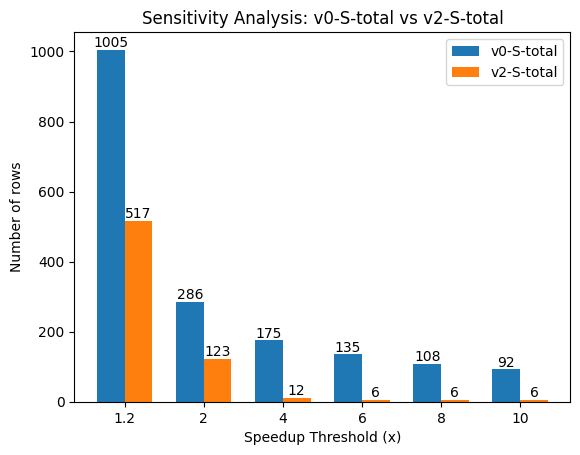

In [619]:
compare_speedups(df, "v0-S-total", "v2-S-total")